# 2. Plot and save figures

This notebook is the single plotting pipeline. It reads only the tables,
TIFFs, and compact plot-data bundles produced by notebook 01. No beam–wire
interaction or free-space propagation is repeated here.

The sections follow the same order as notebook 01. Figures are written directly
to their established output directories; a final manifest indexes them without
making duplicate copies.


## Shared plotting setup


In [1]:
from pathlib import Path
import os
import pickle
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from PIL import Image
from scipy import interpolate

START_DIR = Path.cwd()
if (START_DIR / "PCI.py").exists():
    SAXS_DIR = START_DIR
elif (START_DIR / "SAXS_asymmetry" / "PCI.py").exists():
    SAXS_DIR = START_DIR / "SAXS_asymmetry"
else:
    raise RuntimeError("Run from the repository root or SAXS_asymmetry/ directory.")
os.chdir(SAXS_DIR)
if str(SAXS_DIR) not in sys.path:
    sys.path.insert(0, str(SAXS_DIR))

import PCI
import rossendorfer_farbenliste as rofl

INPUT_DIR = SAXS_DIR / "inputs"
OUTPUT_DIR = SAXS_DIR / "outputs"
PLOT_DATA_DIR = OUTPUT_DIR / "combined_plot_data"
SAXS_PICKLE_DIR = INPUT_DIR / "experimental" / "SAXSData"
ERIK_DIR = INPUT_DIR / "experimental" / "Erik"
LINGEN_REFERENCE_PATH = INPUT_DIR / "reference" / "DivSAXS_asymmetry_Mark1300_6um_lg.dat"
TRANSMISSION_SCAN_PATH = INPUT_DIR / "experimental" / "MotoPosition_Zyla_r0484.dat"

N_GRID = 4096
PIXEL_SIZE = 8 * PCI.nm
Z_SAXS_DETECTOR = 1.31 * PCI.m
Q_MAX = np.pi / PIXEL_SIZE
Q_AXIS = np.linspace(-Q_MAX, Q_MAX, N_GRID)
Q_STEP = 2 * np.pi / (N_GRID * PIXEL_SIZE)
Q_MIN = 0.10
Q_COMPARE_MAX = 0.30
EXPERIMENTAL_RUNS = (528, 534, 546)

# Shared imshow extents, so every figure uses the same axes conventions.
SAMPLE_AXIS_UM = (np.arange(N_GRID) - N_GRID // 2) * PIXEL_SIZE / PCI.um
SAMPLE_EXTENT_UM = [SAMPLE_AXIS_UM[0], SAMPLE_AXIS_UM[-1]] * 2
Q_EXTENT = [-Q_STEP * N_GRID / 2, Q_STEP * N_GRID / 2] * 2

plt.rcParams.update({"figure.facecolor": "white", "axes.grid": False})

def require(path):
    path = Path(path)
    if not path.exists():
        raise RuntimeError(f"Missing {path}; run 01_calculate_and_save_data.ipynb first.")
    return path

def load_tiff(path):
    with Image.open(require(path)) as image:
        return np.asarray(image, dtype=np.float32).copy()

def save_figure(fig, path, *, dpi=200):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    return path

def offset_tag(offset_um, decimals=1):
    return f"{offset_um:+.{decimals}f}".replace("+", "p").replace("-", "m").replace(".", "p")

def load_run_halves(run):
    """Return the measured (positive q, left, right) half-profiles for one run."""
    path = SAXS_PICKLE_DIR / f"profiles_cleaned_p3129_r{run:04d}.pickle"
    with require(path).open("rb") as stream:
        q_positive, left, right = pickle.load(stream)[:3]
    return (
        np.asarray(q_positive, dtype=float),
        np.nan_to_num(np.asarray(left, dtype=float), nan=0.0),
        np.nan_to_num(np.asarray(right, dtype=float), nan=0.0),
    )

def load_pointing_profiles():
    """Mirror each measured half-profile into a full signed-q pointing lineout."""
    scales = {528: 50e3, 534: 80e3, 546: 80e3}
    profiles = {}
    for run, scale in scales.items():
        q_positive, left, right = load_run_halves(run)
        q = np.concatenate((np.flip(-q_positive)[:-1], q_positive))
        lineout = np.concatenate((np.flip(left)[:-1], right))
        profiles[run] = (q, lineout / lineout.max() / scale)
    return profiles

def load_realistic_experimental_profile(run):
    """Sorted signed-q profile normalized over the Q_MIN..Q_COMPARE_MAX band."""
    q_positive, left, right = load_run_halves(run)
    keep = np.isfinite(q_positive) & (q_positive >= 0)
    q_positive, left, right = q_positive[keep], left[keep], right[keep]
    order = np.argsort(q_positive)
    q_positive, left, right = q_positive[order], left[order], right[order]
    q_signed = np.concatenate((-q_positive[:0:-1], q_positive))
    intensity = np.concatenate((left[:0:-1], right))
    scale_mask = (np.abs(q_signed) >= Q_MIN) & (np.abs(q_signed) <= Q_COMPARE_MAX)
    outer = q_positive >= Q_MIN
    return {
        "q": q_signed,
        "normalized": intensity / np.max(intensity[scale_mask]),
        "left_fraction": left[outer].sum() / (left[outer].sum() + right[outer].sum()),
    }

def load_erik_reference():
    """Externally supplied collimated-beam left/right scan and the motor scan."""
    ratio = np.load(require(ERIK_DIR / "left_div_right.npy")).astype(float)
    total = np.load(require(ERIK_DIR / "left_plus_right.npy")).astype(float)
    right = total / (1 + ratio)
    return {
        "offsets_um": np.load(require(ERIK_DIR / "pos_grid.npy")).astype(float) / 1e3,
        "left": ratio * right,
        "right": right,
        "total": total,
        "left_fraction": ratio / (1 + ratio),
        "motor_offsets_um": np.load(require(ERIK_DIR / "motor_positions_um.npy")),
        "motor_left_fraction": np.load(require(ERIK_DIR / "left_div_left_right_exp.npy")),
    }

def load_transmission_scan():
    """XGM-normalized r0484 transmission, re-zeroed on its minimum."""
    data = np.loadtxt(require(TRANSMISSION_SCAN_PATH))
    if data.shape[0] != 3 and data.shape[1] == 3:
        data = data.T
    minimum = int(np.nanargmin(data[2]))
    return (data[0] - data[0, minimum]) * 1e3, data[2] / np.nanmax(data[2])

# Loaded once here so every section below shares the same experimental references.
pointing_experimental = load_pointing_profiles()
erik = load_erik_reference()
transmission_position_um, transmission = load_transmission_scan()

print(f"Plotting artifacts from: {OUTPUT_DIR.resolve()}")


PCI successfully compiled. You can get more help by typing 'PCI.help()'


  This program comes with ABSOLUTELY NO WARRANTY; for details type `show w'.
  This is free software, and you are welcome to redistribute it
  under certain conditions; type `show c' for details.
Plotting artifacts from: C:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs


## 1. Clean SAXS figures


In [2]:
SAXS_OUTPUT_DIR = OUTPUT_DIR / "saxs"
SAXS_TABLE_DIR = SAXS_OUTPUT_DIR / "tables"
SAXS_FIGURE_DIR = SAXS_OUTPUT_DIR / "figures"
SAXS_TIFF_ROOT = SAXS_OUTPUT_DIR / "detector_tiffs" / f"Data_{PIXEL_SIZE:g}nm"

clean_cases = {
    "mark1300_7p1um": {
        "label": "Mark1300 divergent, 7.1 µm FWHM at target",
        "table": SAXS_TABLE_DIR / "DivSAXS_asymmetry_Mark1300_7p1um.dat",
    },
    "collimated_7p1um": {
        "label": "Collimated (large-root), 7.1 µm FWHM at target",
        "table": SAXS_TABLE_DIR / "CollimatedSAXS_asymmetry_Mark1300_7p1um.dat",
    },
}
clean_profiles = np.load(require(PLOT_DATA_DIR / "clean_saxs_profiles.npz"))
pointing_q = clean_profiles["q_reference"]

for case_name, case in clean_cases.items():
    table = np.loadtxt(require(case["table"]))
    offsets_um = table[:, 0] / 1e3
    fractions = table[:, 1] / (table[:, 1] + table[:, 2])
    lineouts = clean_profiles[f"{case_name}_lineouts"]
    results_dir = SAXS_FIGURE_DIR / f"Results_{PIXEL_SIZE:g}nm" / case_name
    data_dir = SAXS_TIFF_ROOT / case_name
    for index, (offset_um, fraction, lineout) in enumerate(
        zip(offsets_um, fractions, lineouts), start=1
    ):
        intensity = load_tiff(data_dir / f"SAXS_Offset{offset_um:.2f}um.tif")
        fig, axes = plt.subplots(2, 1, figsize=(10, 8))
        image = axes[0].imshow(
            intensity, origin="lower", extent=Q_EXTENT, aspect="auto",
            cmap="inferno", norm=LogNorm(vmin=1e-11, vmax=5e-8),
        )
        axes[0].set(
            xlabel=r"$Q_x$ [nm$^{-1}$]", ylabel=r"$Q_y$ [nm$^{-1}$]",
            title=f"{case['label']}, offset {offset_um:.1f} µm, L/(L+R)={fraction:.4f}",
            xlim=(-0.4, 0.4), ylim=(-0.005, 0.005),
        )
        fig.colorbar(image, ax=axes[0], label="Intensity")
        axes[1].semilogy(pointing_q, lineout, "--", label=f"Simulated {offset_um:.1f} µm")
        for run, (q_values, experimental) in pointing_experimental.items():
            axes[1].semilogy(q_values, experimental, "o-", markersize=3, label=f"Exp. Run {run}")
        axes[1].set(
            xlabel=r"$Q_x$ [nm$^{-1}$]", ylabel="Normalized intensity",
            xlim=(-0.4, 0.4), ylim=(1e-8, 5e-4),
        )
        axes[1].grid(alpha=0.25)
        axes[1].legend()
        fig.tight_layout()
        output_path = results_dir / (
            f"SAXS_offset{offset_um:.1f}um_{case_name}_"
            f"Pix{PIXEL_SIZE:g}nm_D{Z_SAXS_DETECTOR / PCI.m:.2f}m.png"
        )
        save_figure(fig, output_path)
        plt.close(fig)
        del intensity
    print(f"Clean SAXS figures: {case_name} ({len(offsets_um)})")


Clean SAXS figures: mark1300_7p1um (41)
Clean SAXS figures: collimated_7p1um (41)


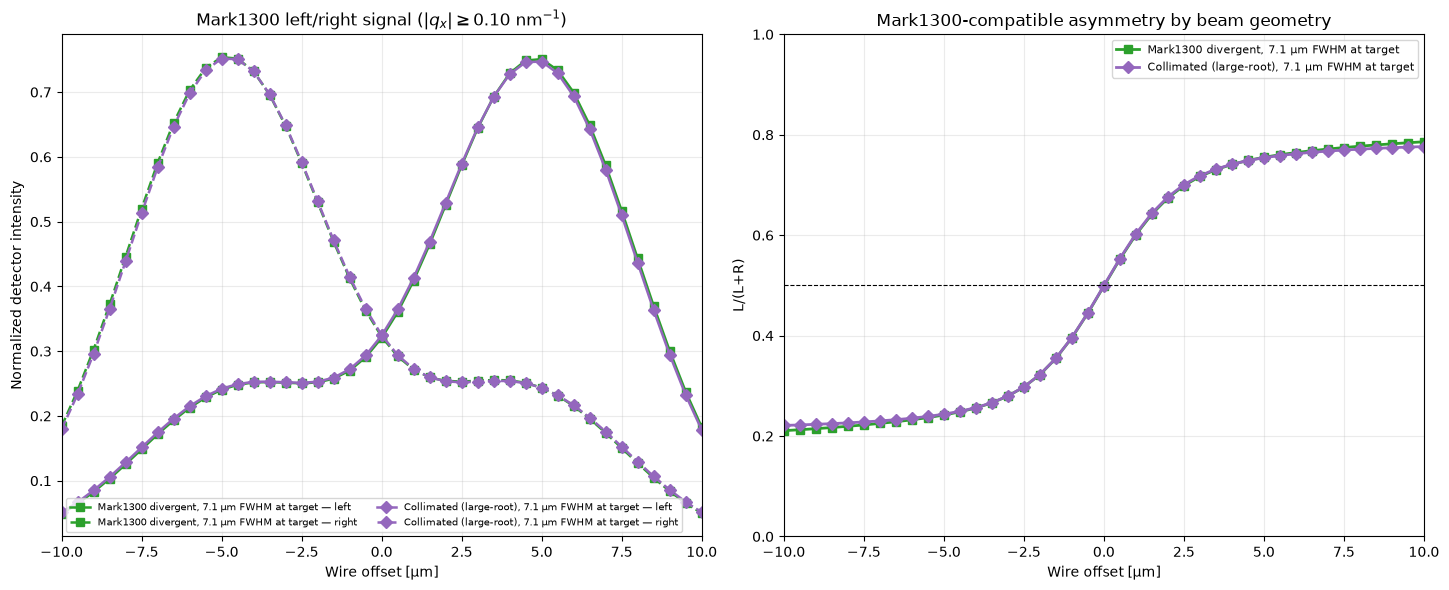

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
styles = {
    "mark1300_7p1um": dict(color="tab:green", marker="s"),
    "collimated_7p1um": dict(color="tab:purple", marker="D"),
}
for case_name, case in clean_cases.items():
    table = np.loadtxt(case["table"])
    offsets_um, left, right = table[:, 0] / 1e3, table[:, 1], table[:, 2]
    scale = np.nanmax(left + right)
    axes[0].plot(offsets_um, left / scale, "-", lw=1.8,
                 label=f"{case['label']} — left", **styles[case_name])
    axes[0].plot(offsets_um, right / scale, "--", lw=1.8,
                 label=f"{case['label']} — right", **styles[case_name])
    axes[1].plot(offsets_um, left / (left + right), "-", lw=2,
                 label=case["label"], **styles[case_name])
axes[0].set(
    xlabel="Wire offset [µm]", ylabel="Normalized detector intensity",
    title=r"Mark1300 left/right signal ($|q_x| \geq 0.10$ nm$^{-1}$)", xlim=(-10, 10),
)
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=7, ncol=2)
axes[1].axhline(0.5, color="k", lw=0.8, ls="--")
axes[1].set(
    xlabel="Wire offset [µm]", ylabel="L/(L+R)",
    title="Mark1300-compatible asymmetry by beam geometry", xlim=(-10, 10), ylim=(0, 1),
)
axes[1].grid(alpha=0.25); axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, SAXS_FIGURE_DIR / "SAXS_Mark1300_collimated_7p1um.png")
plt.show()


## 2. SAXS asymmetry-method figures and gallery


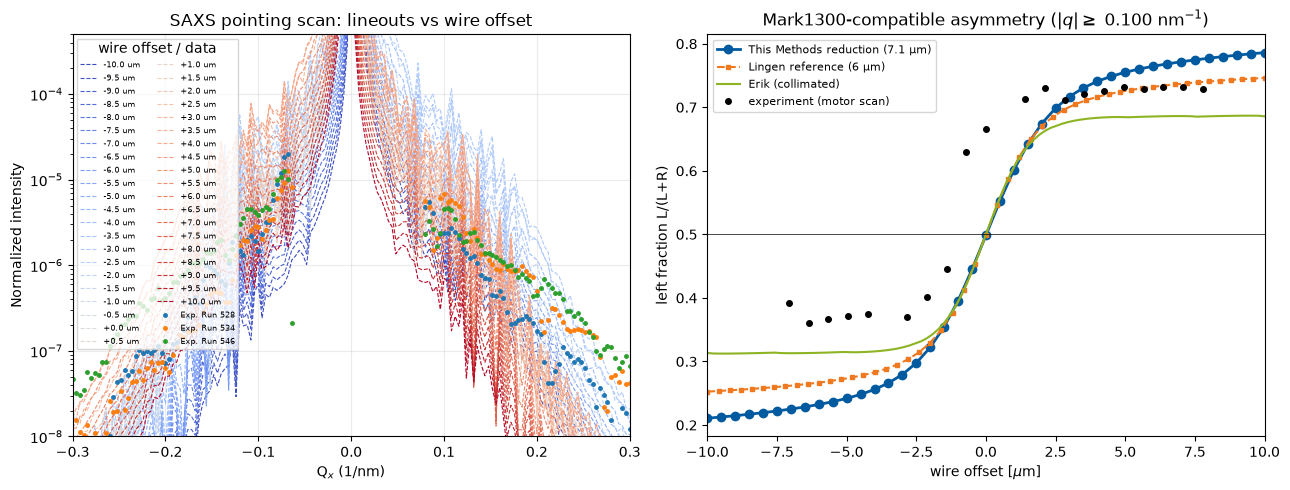

In [4]:
METHODS_DIR = OUTPUT_DIR / "methods"
METHODS_TABLE_DIR = METHODS_DIR / "tables"
METHODS_FIGURE_DIR = METHODS_DIR / "figures"
METHODS_MOVIE_DIR = METHODS_DIR / "movie" / "7p1um"
METHODS_FRAME_DIR = METHODS_MOVIE_DIR / "frames"
METHODS_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
METHODS_FRAME_DIR.mkdir(parents=True, exist_ok=True)

methods_profiles = np.load(require(PLOT_DATA_DIR / "methods_pointing_profiles.npz"))
methods_table = np.loadtxt(require(METHODS_TABLE_DIR / "DivSAXS_asymmetry_Methods_7p1um.dat"))
methods_offsets_um = methods_table[:, 0] / 1e3
methods_fraction = methods_table[:, 1] / (methods_table[:, 1] + methods_table[:, 2])
lingen_table = np.loadtxt(require(LINGEN_REFERENCE_PATH))
lingen_offsets_um = lingen_table[:, 0] / 1e3
lingen_fraction = lingen_table[:, 1] / (lingen_table[:, 1] + lingen_table[:, 2])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cmap = plt.cm.coolwarm
for offset_um, lineout in zip(methods_profiles["offsets_um"], methods_profiles["lineouts"]):
    axes[0].semilogy(
        methods_profiles["q"], lineout, "--",
        color=cmap((offset_um - methods_offsets_um.min()) / np.ptp(methods_offsets_um)),
        lw=0.8, label=f"{offset_um:+.1f} um",
    )
for run, (q_values, experimental) in pointing_experimental.items():
    axes[0].semilogy(q_values, experimental, "o", ms=2.5, label=f"Exp. Run {run}")
axes[0].set(
    xlim=(-0.3, 0.3), ylim=(1e-8, 5e-4), xlabel=r"Q$_x$ (1/nm)",
    ylabel="Normalized intensity", title="SAXS pointing scan: lineouts vs wire offset",
)
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=6, ncol=2, title="wire offset / data")
axes[1].plot(methods_offsets_um, methods_fraction, "o-", color=rofl.b(), lw=2,
             label="This Methods reduction (7.1 µm)")
axes[1].plot(lingen_offsets_um, lingen_fraction, "s--", ms=3, color=rofl.o(),
             label="Lingen reference (6 µm)")
axes[1].plot(erik["offsets_um"], erik["left_fraction"], "-", color=rofl.g(), label="Erik (collimated)")
axes[1].plot(erik["motor_offsets_um"], erik["motor_left_fraction"], "ko", ms=4, label="experiment (motor scan)")
axes[1].axhline(0.5, color="k", lw=0.5)
axes[1].set(
    xlabel=r"wire offset [$\mu$m]", ylabel="left fraction L/(L+R)", xlim=(-10, 10),
    title=rf"Mark1300-compatible asymmetry ($|q| \geq$ {Q_MIN:.3f} nm$^{{-1}}$)",
)
axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
save_figure(fig, METHODS_FIGURE_DIR / "01_offset_scan.png")
plt.show()


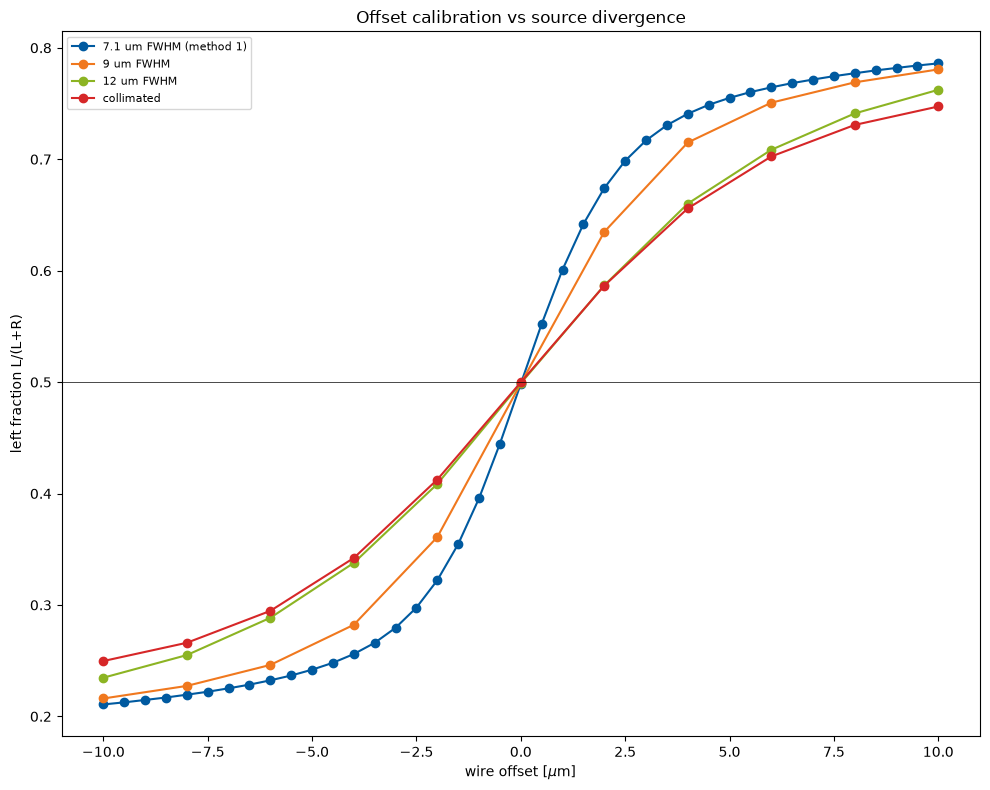

In [5]:
divergence = np.genfromtxt(
    require(METHODS_TABLE_DIR / "DivSAXS_divergence_vs_offset_Methods.dat"),
    delimiter="\t", names=True, dtype=None, encoding="utf-8",
)
fig, ax = plt.subplots(figsize=(10, 8))
case_order = list(dict.fromkeys(divergence["case"].tolist()))
colors = [rofl.b(), rofl.o(), rofl.g(), "tab:red"]
for case_name, color in zip(case_order, colors):
    rows = divergence[divergence["case"] == case_name]
    ax.plot(rows["offset_um"], rows["left_fraction"], "o-", color=color, label=case_name)
ax.axhline(0.5, color="k", lw=0.5)
ax.set(
    xlabel=r"wire offset [$\mu$m]", ylabel="left fraction L/(L+R)",
    title="Offset calibration vs source divergence",
)
ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, METHODS_FIGURE_DIR / "05_divergence_scan.png")
plt.show()


In [6]:
gallery_offsets_um = np.arange(-10.0, 10.0 + 0.25, 0.5)
gif_frames = []
pci_half_width_um = N_GRID * PIXEL_SIZE / (2 * PCI.um)
q_half_width = float(np.abs(Q_AXIS).max())
for frame_index, offset_um in enumerate(gallery_offsets_um):
    pci = load_tiff(METHODS_MOVIE_DIR / f"DivPCI_AfterSample_Offset{offset_um:.2f}um.tif")
    saxs = load_tiff(METHODS_MOVIE_DIR / f"DivSAXS_Offset{offset_um:.2f}um.tif")
    pci_max, saxs_max = float(np.nanmax(pci)), float(np.nanmax(saxs))
    step = max(1, N_GRID // 1024)
    pci_display, saxs_display = pci[::step, ::step], saxs[::step, ::step]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    axes[0].imshow(
        pci_display, origin="lower", cmap=rofl.cmap(),
        extent=[-pci_half_width_um, pci_half_width_um] * 2, vmin=0, vmax=pci_max,
    )
    axes[0].set(
        xlabel="Sample-plane x [µm]", ylabel="Sample-plane y [µm]",
        title=r"PCI immediately after sample: $|E_{\rm exit}|^2$",
    )
    axes[1].imshow(
        saxs_display, origin="lower", cmap=rofl.cmap(),
        extent=[-q_half_width, q_half_width] * 2,
        norm=LogNorm(vmin=max(saxs_max * 1e-9, np.finfo(float).tiny), vmax=saxs_max),
        aspect="auto",
    )
    axes[1].set(
        xlabel=r"Q$_x$ [1/nm]", ylabel=r"Q$_y$ [1/nm]",
        title="SAXS at detector (log scale)", ylim=(-0.08, 0.08),
    )
    fig.suptitle(f"Wire offset {offset_um:+.1f} µm — PCI exit and SAXS detector")
    fig.tight_layout()
    frame_path = METHODS_FRAME_DIR / f"frame{frame_index:02d}_offset{offset_um:+.1f}um.png"
    save_figure(fig, frame_path, dpi=120)
    plt.close(fig)
    with Image.open(frame_path) as frame:
        gif_frames.append(frame.convert("RGB").copy())
    del pci, saxs
gif_path = METHODS_MOVIE_DIR / "PCI_after_sample_SAXS_detector_offset_scan.gif"
gif_frames[0].save(
    gif_path, save_all=True, append_images=gif_frames[1:], duration=350, loop=0
)
print(f"Methods gallery: {gif_path}")


Methods gallery: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\methods\movie\7p1um\PCI_after_sample_SAXS_detector_offset_scan.gif


## 3. Clean PCI figures


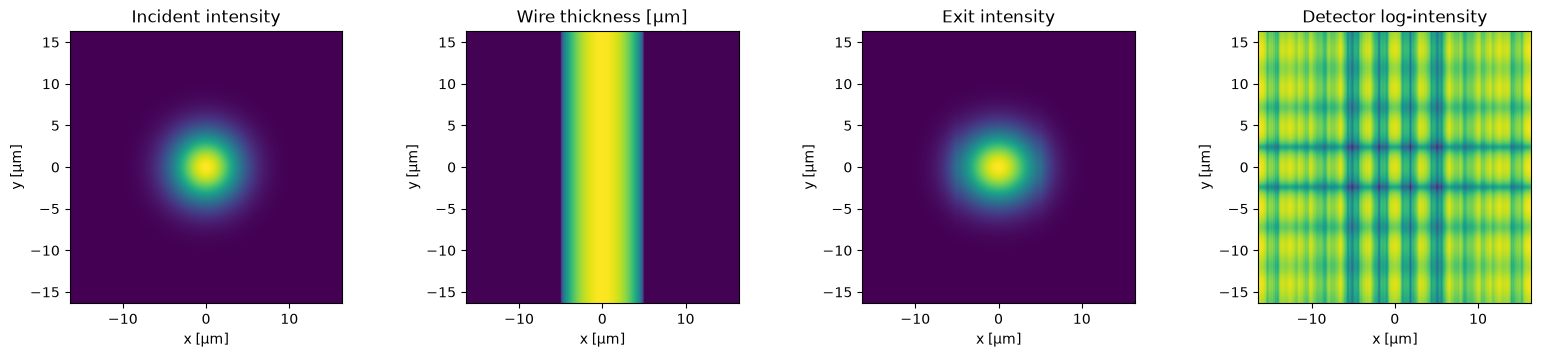

In [7]:
CLEAN_PCI_DIR = OUTPUT_DIR / "clean_pci"
fields = np.load(require(PLOT_DATA_DIR / "clean_pci_fields.npz"))
detector_intensity = load_tiff(CLEAN_PCI_DIR / "clean_pci_detector_intensity.tif")
extent_um = fields["extent_um"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].imshow(fields["incident_intensity"], extent=extent_um, origin="lower")
axes[0].set_title("Incident intensity")
axes[1].imshow(fields["thickness_um"], extent=extent_um, origin="lower")
axes[1].set_title("Wire thickness [µm]")
axes[2].imshow(fields["exit_intensity"], extent=extent_um, origin="lower")
axes[2].set_title("Exit intensity")
axes[3].imshow(
    np.log10(detector_intensity + detector_intensity.max() * 1e-8),
    extent=extent_um, origin="lower",
)
axes[3].set_title("Detector log-intensity")
for axis in axes:
    axis.set_xlabel("x [µm]"); axis.set_ylabel("y [µm]")
fig.tight_layout()
save_figure(fig, CLEAN_PCI_DIR / "clean_pci_field_overview.png")
plt.show()


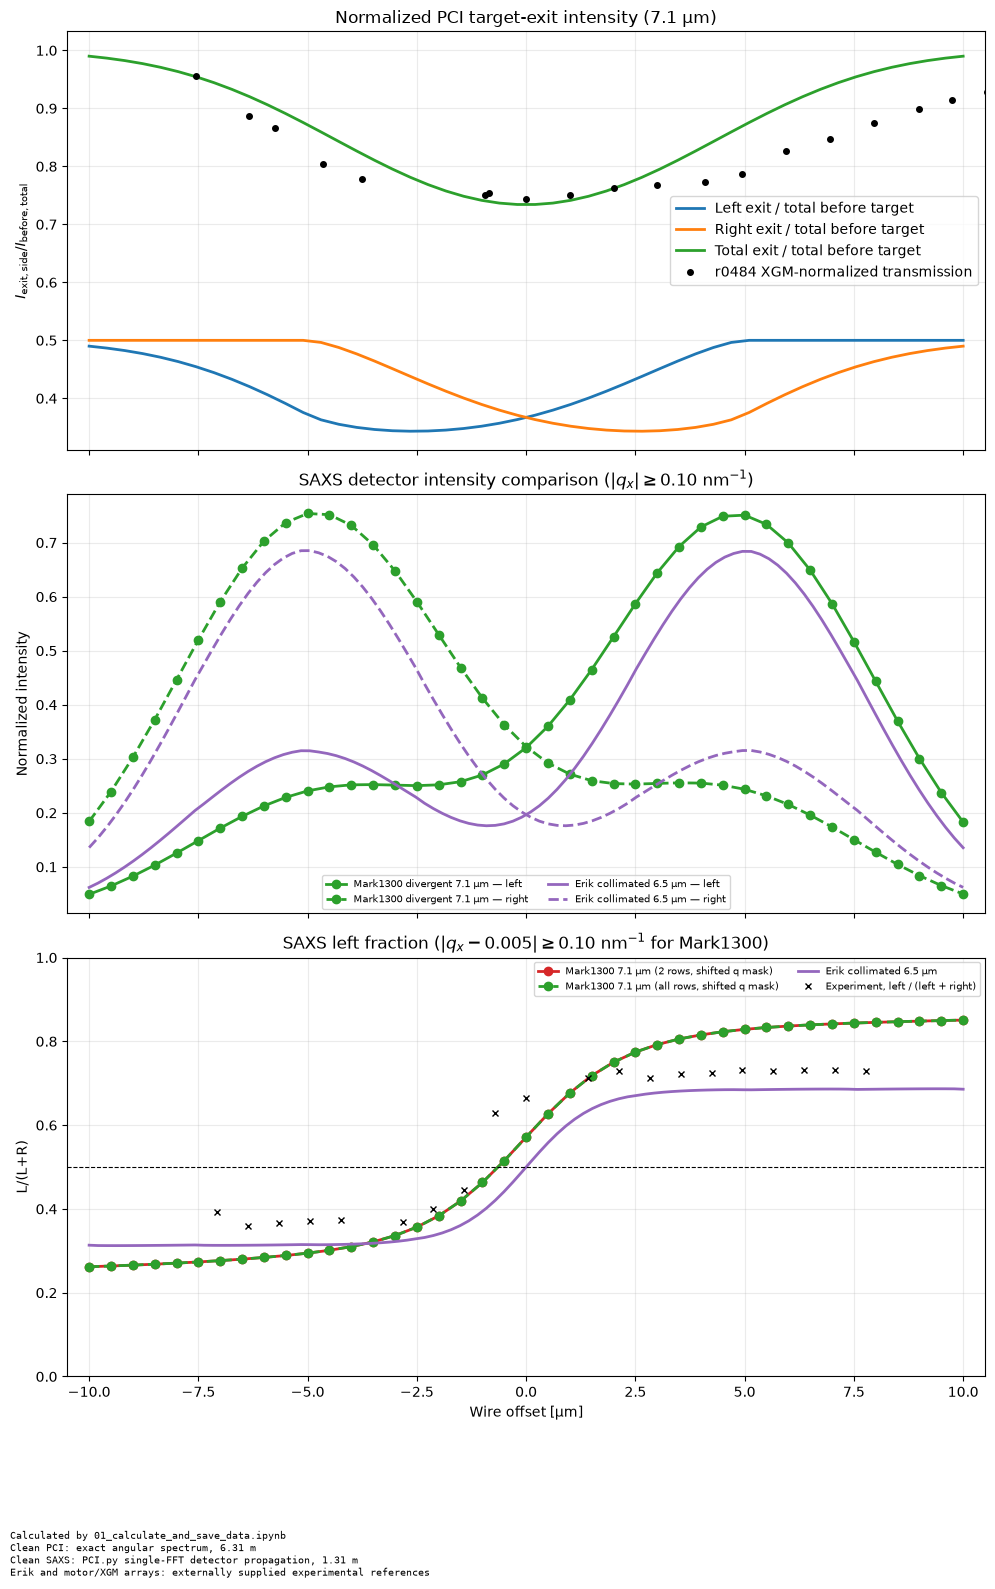

In [8]:
clean_pci = np.loadtxt(require(CLEAN_PCI_DIR / "pci_exit_left_right_vs_offset.dat"))
saxs_7 = np.loadtxt(require(SAXS_TABLE_DIR / "DivSAXS_asymmetry_Mark1300_7p1um.dat"))
q_shifted = np.loadtxt(require(CLEAN_PCI_DIR / "mark1300_7p1um_shifted_q_mask_left_fraction.dat"))

fig, axes = plt.subplots(3, 1, figsize=(10, 16), sharex=True)
axes[0].plot(clean_pci[:, 0], clean_pci[:, 1], color="tab:blue", lw=2,
             label="Left exit / total before target")
axes[0].plot(clean_pci[:, 0], clean_pci[:, 2], color="tab:orange", lw=2,
             label="Right exit / total before target")
axes[0].plot(clean_pci[:, 0], clean_pci[:, 3], color="tab:green", lw=2,
             label="Total exit / total before target")
axes[0].plot(transmission_position_um, transmission, "ko", ms=4,
             label="r0484 XGM-normalized transmission")
axes[0].set(
    ylabel=r"$I_{\mathrm{exit,side}}/I_{\mathrm{before,total}}$",
    title="Normalized PCI target-exit intensity (7.1 µm)", xlim=(-10.5, 10.5),
)
axes[0].legend()

saxs_7_offsets_um, saxs_7_left, saxs_7_right = saxs_7[:, 0] / 1e3, saxs_7[:, 1], saxs_7[:, 2]
saxs_7_scale = np.nanmax(saxs_7_left + saxs_7_right)
axes[1].plot(saxs_7_offsets_um, saxs_7_left / saxs_7_scale, "o-", color="tab:green", lw=2,
             label="Mark1300 divergent 7.1 µm — left")
axes[1].plot(saxs_7_offsets_um, saxs_7_right / saxs_7_scale, "o--", color="tab:green", lw=2,
             label="Mark1300 divergent 7.1 µm — right")
erik_scale = np.nanmax(erik["total"])
axes[1].plot(erik["offsets_um"], erik["left"] / erik_scale, "-", color="tab:purple", lw=2,
             label="Erik collimated 6.5 µm — left")
axes[1].plot(erik["offsets_um"], erik["right"] / erik_scale, "--", color="tab:purple", lw=2,
             label="Erik collimated 6.5 µm — right")
axes[1].set(
    ylabel="Normalized intensity",
    title=r"SAXS detector intensity comparison ($|q_x| \geq 0.10$ nm$^{-1}$)",
)
axes[1].legend(fontsize=7, ncol=2)

axes[2].plot(q_shifted[:, 0], q_shifted[:, 1], "o-", color="tab:red", lw=2,
             label="Mark1300 7.1 µm (2 rows, shifted q mask)")
axes[2].plot(q_shifted[:, 0], q_shifted[:, 2], "o--", color="tab:green", lw=2,
             label="Mark1300 7.1 µm (all rows, shifted q mask)")
axes[2].plot(erik["offsets_um"], erik["left_fraction"], "-", color="tab:purple", lw=2,
             label="Erik collimated 6.5 µm")
axes[2].plot(erik["motor_offsets_um"], erik["motor_left_fraction"], "kx", ms=5,
             label="Experiment, left / (left + right)")
axes[2].axhline(0.5, color="k", lw=0.8, ls="--")
axes[2].set(
    xlabel="Wire offset [µm]", ylabel="L/(L+R)", ylim=(0, 1),
    title=r"SAXS left fraction ($|q_x - 0.005| \geq 0.10$ nm$^{-1}$ for Mark1300)",
)
axes[2].legend(fontsize=7, ncol=2)
for axis in axes:
    axis.grid(alpha=0.25)
fig.text(
    0.01, 0.01,
    "Calculated by 01_calculate_and_save_data.ipynb\n"
    "Clean PCI: exact angular spectrum, 6.31 m\n"
    "Clean SAXS: PCI.py single-FFT detector propagation, 1.31 m\n"
    "Erik and motor/XGM arrays: externally supplied experimental references",
    ha="left", va="bottom", fontsize=7, family="monospace",
)
fig.tight_layout(rect=(0, 0.10, 1, 1))
save_figure(fig, CLEAN_PCI_DIR / "clean_pci_saxs_mark1300_left_right_vs_offset.png")
plt.show()


## 4. Realistic-profile figures


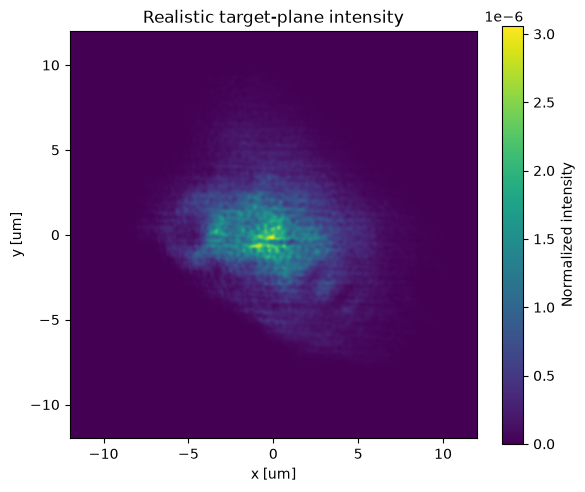

In [9]:
REALISTIC_DIR = OUTPUT_DIR / "realistic_profile"
REALISTIC_TABLE_DIR = REALISTIC_DIR / "tables"
REALISTIC_FIGURE_DIR = REALISTIC_DIR / "figures"
REALISTIC_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

incident = np.load(require(PLOT_DATA_DIR / "realistic_incident_intensity.npy"))
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(
    incident, origin="lower", extent=SAMPLE_EXTENT_UM, cmap="viridis", vmin=0, vmax=incident.max()
)
ax.set(
    xlabel="x [um]", ylabel="y [um]", title="Realistic target-plane intensity",
    xlim=(-12, 12), ylim=(-12, 12),
)
fig.colorbar(image, ax=ax, label="Normalized intensity")
fig.tight_layout()
save_figure(fig, REALISTIC_FIGURE_DIR / "00_realistic_incident_profile.png")
plt.show()
del incident


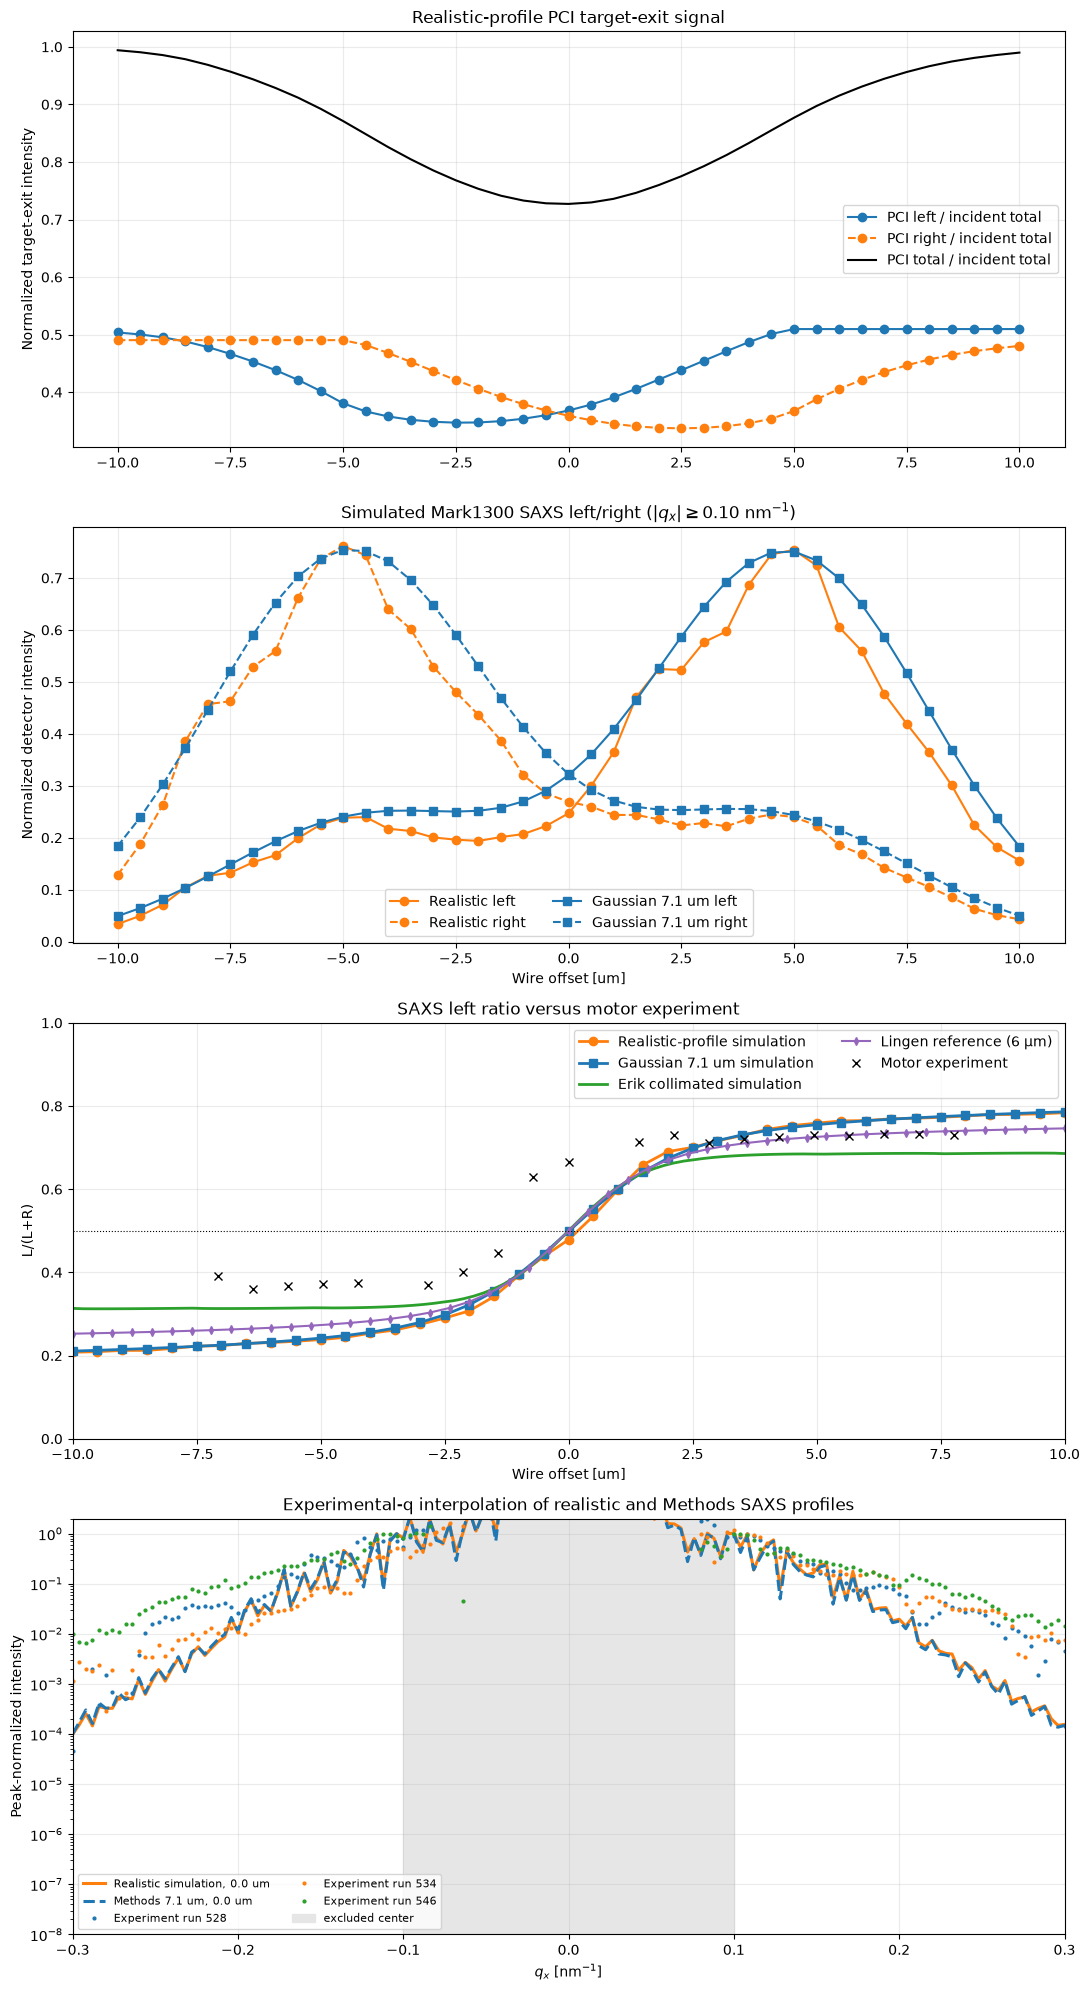

In [10]:
realistic_pci = np.loadtxt(require(REALISTIC_TABLE_DIR / "realistic_profile_pci_exit_left_right.dat"))
realistic_saxs = np.loadtxt(require(REALISTIC_TABLE_DIR / "realistic_profile_saxs_left_right.dat"))
realistic_bundle = np.load(require(PLOT_DATA_DIR / "realistic_saxs_lineouts.npz"))
realistic_offsets_um = realistic_pci[:, 0]
realistic_lineouts = realistic_bundle["lineouts"]
realistic_q_axis = realistic_bundle["q_axis"]
realistic_experimental = {run: load_realistic_experimental_profile(run) for run in EXPERIMENTAL_RUNS}

gaussian = np.loadtxt(require(SAXS_TABLE_DIR / "DivSAXS_asymmetry_Mark1300_7p1um.dat"))
gaussian_offsets_um = gaussian[:, 0] / 1e3
gaussian_left, gaussian_right = gaussian[:, 1], gaussian[:, 2]
gaussian_total = gaussian_left + gaussian_right
lingen = np.loadtxt(require(LINGEN_REFERENCE_PATH))
methods_zero_index = int(np.argmin(np.abs(methods_profiles["offsets_um"])))
methods_profile_q = methods_profiles["q"]
methods_profile = methods_profiles["lineouts"][methods_zero_index].astype(float)

real_pci_left, real_pci_right = realistic_pci[:, 1], realistic_pci[:, 2]
real_pci_total = realistic_pci[:, 3]
incident_total = np.nanmedian(real_pci_total / realistic_pci[:, 5])
real_saxs_left, real_saxs_right = realistic_saxs[:, 1], realistic_saxs[:, 2]
real_saxs_total = real_saxs_left + real_saxs_right

fig, axes = plt.subplots(4, 1, figsize=(11, 20))
axes[0].plot(realistic_offsets_um, real_pci_left / incident_total, "o-", label="PCI left / incident total")
axes[0].plot(realistic_offsets_um, real_pci_right / incident_total, "o--", label="PCI right / incident total")
axes[0].plot(realistic_offsets_um, real_pci_total / incident_total, "k-", label="PCI total / incident total")
axes[0].set(ylabel="Normalized target-exit intensity", title="Realistic-profile PCI target-exit signal")
axes[0].legend()

real_scale, gaussian_scale = real_saxs_total.max(), gaussian_total.max()
axes[1].plot(realistic_offsets_um, real_saxs_left / real_scale, "o-", color="tab:orange", label="Realistic left")
axes[1].plot(realistic_offsets_um, real_saxs_right / real_scale, "o--", color="tab:orange", label="Realistic right")
axes[1].plot(gaussian_offsets_um, gaussian_left / gaussian_scale, "s-", color="tab:blue", label="Gaussian 7.1 um left")
axes[1].plot(gaussian_offsets_um, gaussian_right / gaussian_scale, "s--", color="tab:blue", label="Gaussian 7.1 um right")
axes[1].set(
    xlabel="Wire offset [um]", ylabel="Normalized detector intensity",
    title=r"Simulated Mark1300 SAXS left/right ($|q_x|\geq0.10$ nm$^{-1}$)",
)
axes[1].legend(ncol=2)

axes[2].plot(realistic_offsets_um, real_saxs_left / real_saxs_total, "o-", lw=2,
             color="tab:orange", label="Realistic-profile simulation")
axes[2].plot(gaussian_offsets_um, gaussian_left / gaussian_total, "s-", lw=2,
             color="tab:blue", label="Gaussian 7.1 um simulation")
axes[2].plot(erik["offsets_um"], erik["left_fraction"], "-", lw=2,
             color="tab:green", label="Erik collimated simulation")
axes[2].plot(lingen[:, 0] / 1e3, lingen[:, 1] / (lingen[:, 1] + lingen[:, 2]),
             "d-", ms=4, color="tab:purple", label="Lingen reference (6 µm)")
axes[2].plot(erik["motor_offsets_um"], erik["motor_left_fraction"], "kx", ms=6, label="Motor experiment")
axes[2].axhline(0.5, color="k", lw=0.8, ls=":")
axes[2].set(
    xlabel="Wire offset [um]", ylabel="L/(L+R)", xlim=(-10, 10), ylim=(0, 1),
    title="SAXS left ratio versus motor experiment",
)
axes[2].legend(ncol=2)

profile_index = int(np.argmin(np.abs(realistic_offsets_um)))
realistic_interp = interpolate.interp1d(
    realistic_q_axis, realistic_lineouts[profile_index], kind="linear", fill_value="extrapolate"
)(methods_profile_q)
profile_mask = (np.abs(methods_profile_q) >= Q_MIN) & (np.abs(methods_profile_q) <= Q_COMPARE_MAX)
realistic_interp /= realistic_interp[profile_mask].max()
methods_profile /= methods_profile[profile_mask].max()
axes[3].semilogy(methods_profile_q, np.maximum(realistic_interp, 1e-10), "-", lw=2.2,
                 color="tab:orange", label="Realistic simulation, 0.0 um")
axes[3].semilogy(methods_profile_q, np.maximum(methods_profile, 1e-10), "--", lw=2.2,
                 color="tab:blue", label="Methods 7.1 um, 0.0 um")
for run, profile in realistic_experimental.items():
    axes[3].semilogy(profile["q"], np.maximum(profile["normalized"], 1e-10), ".", ms=4,
                     label=f"Experiment run {run}")
axes[3].axvspan(-Q_MIN, Q_MIN, color="0.9", label="excluded center")
axes[3].set(
    xlabel=r"$q_x$ [nm$^{-1}$]", ylabel="Peak-normalized intensity",
    xlim=(-Q_COMPARE_MAX, Q_COMPARE_MAX), ylim=(1e-8, 2),
    title="Experimental-q interpolation of realistic and Methods SAXS profiles",
)
axes[3].legend(fontsize=8, ncol=2)
for axis in axes:
    axis.grid(alpha=0.25)
fig.tight_layout()
save_figure(fig, REALISTIC_FIGURE_DIR / "01_realistic_pci_saxs_left_right.png")
plt.show()


## 5. Gaussian experimental-comparison figures


In [11]:
EXPERIMENTAL_DIR = OUTPUT_DIR / "experimental_comparison"
EXPERIMENTAL_TABLE_DIR = EXPERIMENTAL_DIR / "tables"
EXPERIMENTAL_PCI_TIFF_DIR = EXPERIMENTAL_DIR / "pci_exit_tiffs"
EXPERIMENTAL_FIGURE_DIR = EXPERIMENTAL_DIR / "figures"
EXPERIMENTAL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Physical PCI and SAXS comparison figures begin in the next cell.


In [12]:
comparison_offsets_um = np.arange(-10.0, 10.0 + 0.25, 0.5)
reference_pci = load_tiff(
    EXPERIMENTAL_PCI_TIFF_DIR / f"analytic_pci_exit_offset_{offset_tag(comparison_offsets_um[0])}um.tif"
)
pci_vmax = float(np.nanmax(reference_pci))
del reference_pci
for offset_um in comparison_offsets_um:
    tag = offset_tag(offset_um)
    pci_image = load_tiff(EXPERIMENTAL_PCI_TIFF_DIR / f"analytic_pci_exit_offset_{tag}um.tif")
    saxs_image = load_tiff(SAXS_TIFF_ROOT / "mark1300_7p1um" / f"SAXS_Offset{offset_um:.2f}um.tif")
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    im0 = axes[0].imshow(
        pci_image, origin="lower", extent=SAMPLE_EXTENT_UM, cmap="inferno",
        vmin=0, vmax=pci_vmax, aspect="equal",
    )
    axes[0].set(
        xlabel="x (um)", ylabel="y (um)",
        title=rf"PCI exit: $|E_{{\rm out}}|^2$, wire offset {offset_um:+.1f} um",
    )
    fig.colorbar(im0, ax=axes[0], label="Intensity (a.u.)")
    im1 = axes[1].imshow(
        saxs_image, origin="lower", extent=Q_EXTENT, cmap="inferno",
        norm=LogNorm(vmin=1e-11, vmax=5e-8), aspect="auto",
    )
    axes[1].set(
        xlabel=r"$q_x$ (1/nm)", ylabel=r"$q_y$ (1/nm)",
        title=f"SAXS after {Z_SAXS_DETECTOR / PCI.m:.2f} m, wire offset {offset_um:+.1f} um",
        xlim=(-0.4, 0.4), ylim=(-0.005, 0.005),
    )
    fig.colorbar(im1, ax=axes[1], label="Intensity (a.u.)")
    fig.tight_layout()
    save_figure(
        fig, EXPERIMENTAL_FIGURE_DIR / f"01_exit_pci_and_saxs_offset_{tag}um.png", dpi=180
    )
    plt.close(fig)
    del pci_image, saxs_image
print(f"Experimental comparison gallery: {len(comparison_offsets_um)} figures")


Experimental comparison gallery: 41 figures


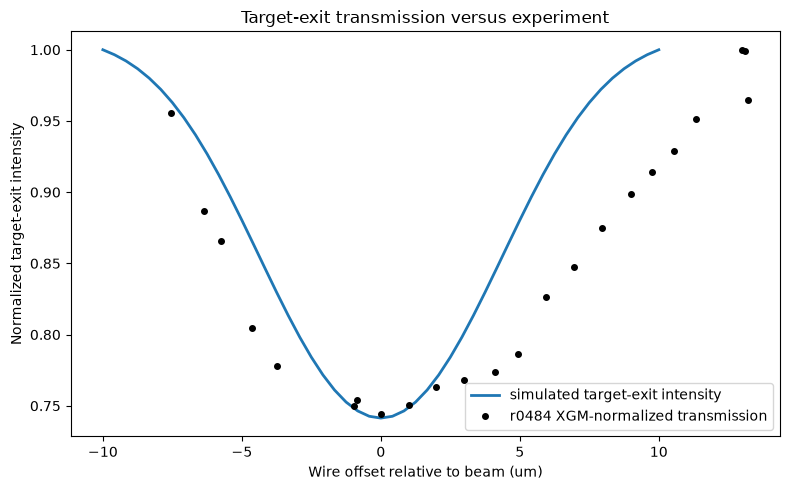

In [13]:
sim_transmission = np.loadtxt(require(EXPERIMENTAL_TABLE_DIR / "analytic_exit_transmission.dat"))
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sim_transmission[:, 0], sim_transmission[:, 1], "-", lw=2,
        label="simulated target-exit intensity")
ax.plot(transmission_position_um, transmission, "ko", ms=4,
        label="r0484 XGM-normalized transmission")
ax.set(
    xlabel="Wire offset relative to beam (um)",
    ylabel="Normalized target-exit intensity",
    title="Target-exit transmission versus experiment",
)
ax.legend(); fig.tight_layout()
save_figure(fig, EXPERIMENTAL_FIGURE_DIR / "04_exit_transmission.png", dpi=180)
plt.show()
